FIRST FIVE RECORDS
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500 

C:\Users\athar\AppData\Local\Temp\ipykernel_8036\2854132636.py:45: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df['Age'].fillna(df['Age'].median(), inplace=True)
C:\Users\athar\AppData\Local\Temp\ipykernel_8036\2854132636.py:48: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assi

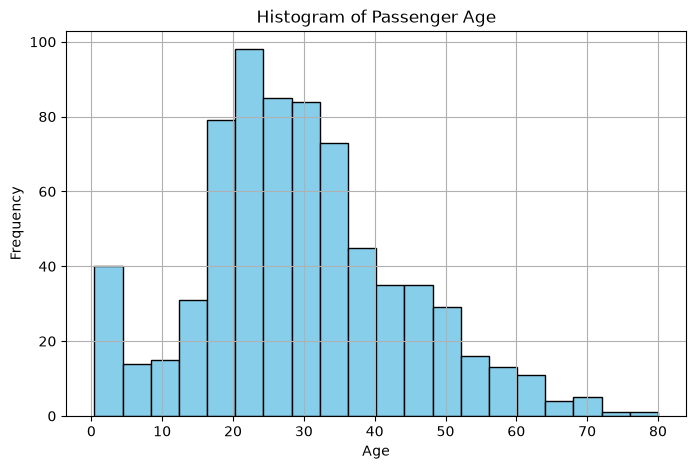

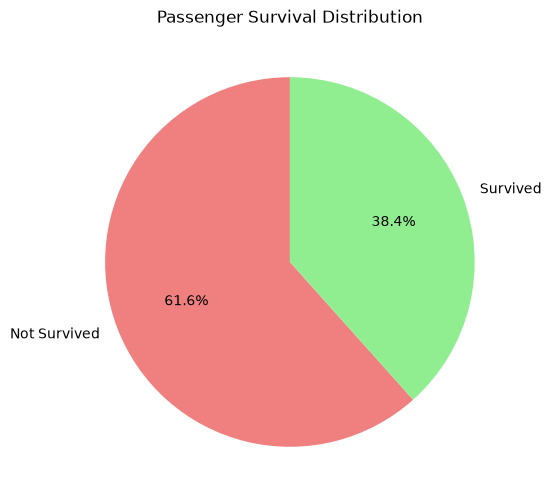

In [4]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------------------------------------
# a. Load and Inspect the Dataset
# ----------------------------------------------------------

# Load dataset
df = pd.read_csv(r"A:\Collge Code\Titanic-Dataset.csv")      # Change filename if required

print("=" * 60)
print("FIRST FIVE RECORDS")
print("=" * 60)
print(df.head())

print("\n" + "=" * 60)
print("DATASET INFORMATION")
print("=" * 60)
print(df.info())

print("\n" + "=" * 60)
print("DATASET SHAPE")
print("=" * 60)
print("Rows and Columns :", df.shape)

print("\n" + "=" * 60)
print("MISSING VALUES")
print("=" * 60)
print(df.isnull().sum())

# ----------------------------------------------------------
# b. Data Cleaning
# ----------------------------------------------------------

print("\n" + "=" * 60)
print("DATA CLEANING")
print("=" * 60)

# Fill missing values

# Age → Median
df['Age'].fillna(df['Age'].median(), inplace=True)

# Embarked → Mode
df['Embarked'].fillna(df['Embarked'].mode()[0], inplace=True)

# Cabin has many missing values, so drop it
if 'Cabin' in df.columns:
    df.drop('Cabin', axis=1, inplace=True)

# Remove duplicate rows
df.drop_duplicates(inplace=True)

print("\nMissing Values After Cleaning")
print(df.isnull().sum())

# ----------------------------------------------------------
# Data Transformation
# ----------------------------------------------------------

print("\n" + "=" * 60)
print("DATA TRANSFORMATION")
print("=" * 60)

# ----------------------------------------------------------
# 1. Convert categorical data into numerical values
# ----------------------------------------------------------

# Sex Encoding
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

# Embarked Encoding
df['Embarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

# ----------------------------------------------------------
# 2. Feature Engineering
# ----------------------------------------------------------

# Create FamilySize feature
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

# Create IsAlone feature
df['IsAlone'] = np.where(df['FamilySize'] == 1, 1, 0)

# ----------------------------------------------------------
# 3. Normalization (Min-Max Scaling)
# ----------------------------------------------------------

df['Age_Normalized'] = (
    df['Age'] - df['Age'].min()
) / (
    df['Age'].max() - df['Age'].min()
)

df['Fare_Normalized'] = (
    df['Fare'] - df['Fare'].min()
) / (
    df['Fare'].max() - df['Fare'].min()
)

# ----------------------------------------------------------
# 4. Binning
# ----------------------------------------------------------

age_bins = [0, 12, 19, 35, 60, 100]
age_labels = ['Child', 'Teen', 'Young Adult', 'Adult', 'Senior']

df['Age_Group'] = pd.cut(
    df['Age'],
    bins=age_bins,
    labels=age_labels
)

print("\nTransformed Dataset")
print(df[['Age',
          'Age_Normalized',
          'Fare',
          'Fare_Normalized',
          'Sex',
          'Embarked',
          'FamilySize',
          'IsAlone',
          'Age_Group']].head(10))

# ----------------------------------------------------------
# c. Summary Statistics
# ----------------------------------------------------------

print("\n" + "=" * 60)
print("SUMMARY STATISTICS")
print("=" * 60)

numeric_columns = ['Age', 'Fare']

for column in numeric_columns:

    print("\nColumn :", column)
    print("------------------------------")
    print("Mean              :", round(df[column].mean(), 2))
    print("Median            :", round(df[column].median(), 2))
    print("Standard Deviation:", round(df[column].std(), 2))
    print("Variance          :", round(df[column].var(), 2))

print("\nComplete Statistical Summary")
print(df.describe())

# ----------------------------------------------------------
# d. Data Visualization
# ----------------------------------------------------------

# Histogram
plt.figure(figsize=(8,5))
plt.hist(df['Age'],
         bins=20,
         color='skyblue',
         edgecolor='black')

plt.title("Histogram of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

# ----------------------------------------------------------

# Pie Chart
survival = df['Survived'].value_counts()

plt.figure(figsize=(6,6))
plt.pie(
    survival,
    labels=['Not Survived', 'Survived'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['lightcoral', 'lightgreen']
)

plt.title("Passenger Survival Distribution")
plt.show()

